# Project: Forecasting Approach Evaluation and Recommendation

The board meeting is in two weeks. Your VP of Sales presented a revenue target of **$4.1M per month by December 2026** — 18% year-over-year growth. The number came from pasting a data export into a generative AI tool and asking it to forecast.

Your data engineering team has already audited the VP's original query and found several bugs that inflated recent revenue figures and made the growth trend look steeper than it actually is. They've corrected the issues and handed you a **clean dataset** (`revenue.csv`) with 60 months of monthly revenue from January 2021 through December 2025.

**Your job:** Take the clean data and figure out what the numbers actually say. Build progressively sophisticated forecasts — from simple baselines through classical ARIMA/SARIMAX to neural models and foundation models — and deliver a stakeholder-ready recommendation with prediction intervals that a non-technical executive can act on.

---

## Deliverables

1. This completed notebook with all phases implemented
2. A comparison table showing all models, their December 2026 forecasts, prediction intervals, and accuracy metrics
3. At least three charts: baseline comparison, classical model forecasts with intervals, modern model forecasts
4. A written recommendation (500–1000 words) answering:
   - What is the realistic range for December 2026 revenue?
   - What should the company plan for instead of $4.1M?
   - Which forecasting approach would you recommend for ongoing use, and why?

## Setup

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from darts import TimeSeries
from darts.models import NBEATSModel, ARIMA as DartsARIMA
from darts.metrics import mae, rmse, mape
from darts.utils.likelihood_models import QuantileRegression
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

VP_TARGET = 4_100_000
HORIZON = 12  # months ahead (Jan 2026 through Dec 2026)

## Load Data

The clean revenue dataset has been prepared by your data engineering team. It contains monthly revenue from January 2021 through December 2025.

Date range: 2021-01-01 to 2025-12-01
Number of months: 60
Revenue range: $1.89M to $3.83M


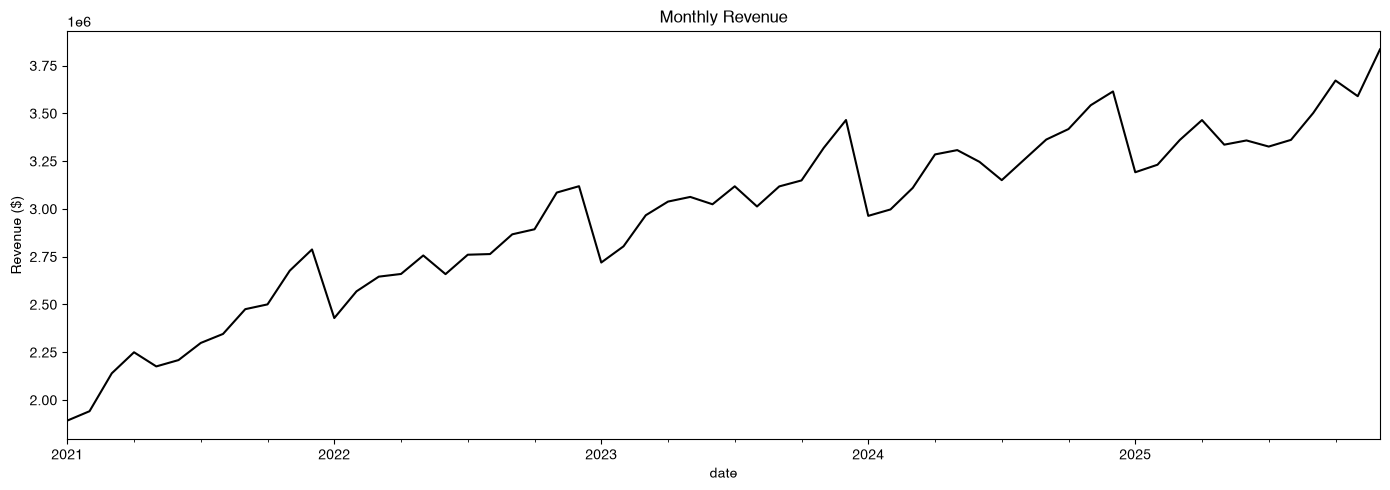

In [73]:
df = pd.read_csv(
    "../data/revenue.csv",
    parse_dates=["date"],
    index_col="date",
)
df.index.freq = "MS"
revenue = df["revenue"]

print(f"Date range: {revenue.index[0].date()} to {revenue.index[-1].date()}")
print(f"Number of months: {len(revenue)}")
print(f"Revenue range: ${revenue.min()/1e6:.2f}M to ${revenue.max()/1e6:.2f}M")

revenue.plot(figsize=(14, 5), color="black", title="Monthly Revenue")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

## Phase 1: Baseline Forecasts

Before reaching for sophisticated models, establish baselines. Compute simple forecasts over a 12-month horizon and compare each to the VP's $4.1M target.

### Helper Functions

The next cell defines four small helpers that every baseline will reuse:

- `naive_forecast` — repeats the last observed value (assumes no trend and no seasonality).
- `moving_average_forecast` — repeats the trailing `window`-month average (smooths short-term noise).
- `trend_forecast` — fits a straight line to the history and extrapolates it (assumes linear growth continues).
- `plot_forecasts` — draws the actuals, every forecast, and the VP target line on one chart.

Each forecast helper returns a `pd.Series` indexed by month-start dates, beginning the month after the last observation.

In [74]:
def naive_forecast(series, horizon):
    """Repeat the last observed value for `horizon` months."""
    last = series.iloc[-1]
    future = pd.date_range(
        start=series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series([last] * horizon, index=future)


def moving_average_forecast(series, window, horizon):
    """Repeat the trailing `window`-month average for `horizon` months."""
    avg = series.iloc[-window:].mean()
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series([avg] * horizon, index=future)


def trend_forecast(series, horizon):
    """Fit a linear trend and extrapolate for `horizon` months."""
    t = np.arange(len(series))
    coeffs = np.polyfit(x=t, y=series.values, deg=1)
    future_t = np.arange(len(series), len(series) + horizon)
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    return pd.Series(np.polyval(coeffs, future_t), index=future)


def plot_forecasts(actuals, forecasts, target=VP_TARGET, title="Forecast Comparison"):
    """Plot actuals and multiple forecast series against the VP target."""
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(actuals.index, actuals / 1e6, color="black", linewidth=1.5, label="Actual")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:red"]
    for i, (name, fc) in enumerate(forecasts.items()):
        ax.plot(fc.index, fc / 1e6, "--", color=colors[i % len(colors)], label=name)
    ax.axhline(
        y=target / 1e6, color="red", linestyle=":", linewidth=2,
        label=f"VP target: ${target/1e6:.1f}M",
    )
    ax.set_ylabel("Revenue ($M)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    return fig

### Generate Baseline Forecasts

Create the naive, 6-month MA, 12-month MA, and linear trend forecasts, then compare each December 2026 forecast to the VP target. Fill in the horizon and window values in the next cell.

In [75]:
# PHASE 1 TODO: Select baseline methods and generate forecasts
#
# Consider: Which baseline methods are most appropriate for this data?
# - Naive: assumes no trend or seasonality
# - Moving average: smooths out short-term fluctuations  
# - Trend (baseline method): assumes linear growth continues
#
# TODO: Decide which window size(s) to try for moving average
# (e.g., 3 months captures recent trends, 12 months captures annual patterns)

# Generate forecasts using chosen methods
forecasts = {
    'Naive': naive_forecast(revenue, horizon=HORIZON),
    '6MA': moving_average_forecast(revenue, window=6, horizon=HORIZON),
    '12MA': moving_average_forecast(revenue, window=12, horizon=HORIZON),
    'Trend': trend_forecast(revenue, horizon=HORIZON)
}

# Compare December 2026 forecasts to VP target
for name, fc in forecasts.items():
    dec_2026 = fc.iloc[-1]
    gap = dec_2026 - VP_TARGET
    print(f"{name}: ${dec_2026/1e6:.2f}M (gap: ${gap/1e6:+.2f}M)")

Naive: $3.83M (gap: $-0.27M)
6MA: $3.55M (gap: $-0.55M)
12MA: $3.44M (gap: $-0.66M)
Trend: $3.98M (gap: $-0.12M)


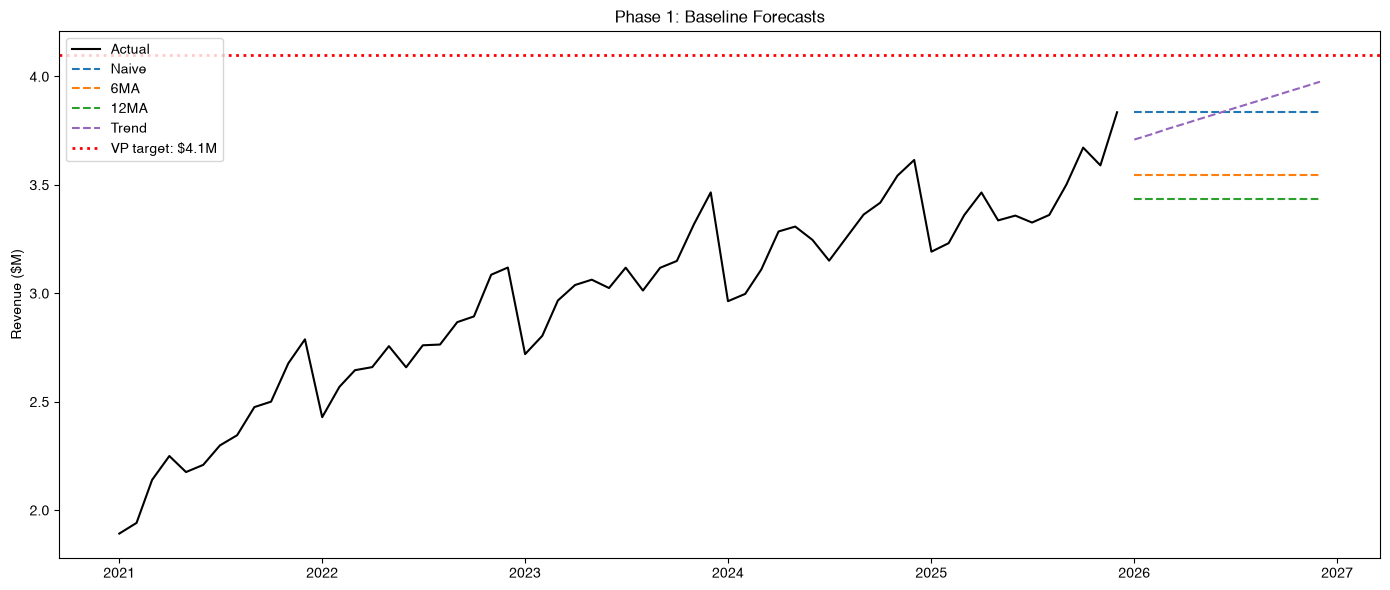

In [7]:
plot_forecasts(revenue, forecasts, VP_TARGET, "Phase 1: Baseline Forecasts");

---

## Phase 2: Classical Models

Fit ARIMA and SARIMAX models. Experiment with different parameter specifications to see which ones converge and produce reasonable forecasts.

### Train/Test Split

Split at December 2024. Train on data through December 2024, test on January 2025 through December 2025.

In [76]:
train = revenue[:'2024-12']
test = revenue['2025-01':]

print(f"Train: {train.index[0]} to {train.index[-1]} ({len(train)} months)")
print(f"Test:  {test.index[0]} to {test.index[-1]} ({len(test)} months)")

Train: 2021-01-01 00:00:00 to 2024-12-01 00:00:00 (48 months)
Test:  2025-01-01 00:00:00 to 2025-12-01 00:00:00 (12 months)


### Phase 2a: ARIMA Parameter Exploration

Start with ARIMA(2,1,1) with a constant trend, then try two alternative **non-seasonal** specifications (seasonality is covered in Phase 2b). If a model fails to converge, try fewer parameters or drop the trend. Compare the candidates by AIC, then evaluate the best one on the test period.

In [77]:
# Start with ARIMA(2,1,1) with trend='c'
arima_211 = SARIMAX(train, order=(2, 1, 1), trend='c').fit(disp=False)
print(f"ARIMA(2,1,1) AIC: {arima_211.aic:.2f}")

ARIMA(2,1,1) AIC: 1258.17


In [78]:
# Try an alternative ARIMA specification: fewer parameters
# ARIMA(0,1,0) with trend='c' is a random walk with drift
arima_alt = SARIMAX(train, order=(0, 1, 0), trend='c').fit(disp=False)
print(f"ARIMA(0,1,0) with trend='c' AIC: {arima_alt.aic:.2f}")

ARIMA(0,1,0) with trend='c' AIC: 1252.18


In [79]:
# Try a third ARIMA specification: same order, but drop the trend
# ARIMA(0,1,0) with trend='n' is a pure random walk (no drift)
arima_third = SARIMAX(train, order=(0, 1, 0), trend='n').fit(disp=False)
print(f"ARIMA(0,1,0) with trend='n' AIC: {arima_third.aic:.2f}")

ARIMA(0,1,0) with trend='n' AIC: 1253.24


In [80]:
# Compare AICs across the ARIMA models (lower is better)
print("ARIMA AIC Comparison:")
print(f"  ARIMA(2,1,1), trend='c': {arima_211.aic:.2f}")
print(f"  ARIMA(0,1,0), trend='c': {arima_alt.aic:.2f}")
print(f"  ARIMA(0,1,0), trend='n': {arima_third.aic:.2f}")

ARIMA AIC Comparison:
  ARIMA(2,1,1), trend='c': 1258.17
  ARIMA(0,1,0), trend='c': 1252.18
  ARIMA(0,1,0), trend='n': 1253.24


In [ ]:
# Select the ARIMA with the lowest AIC from the comparison above
best_arima = arima_alt  # options: arima_211, arima_alt, arima_third

# Forecast the test period (January 2025 through December 2025)
arima_forecast = best_arima.get_forecast(steps=HORIZON)
arima_mean = arima_forecast.predicted_mean

arima_mae = np.mean(np.abs(arima_mean - test))
arima_rmse = np.sqrt(np.mean(np.square(arima_mean - test)))

print(f"Best ARIMA Test MAE: ${arima_mae:,.0f}")
print(f"Best ARIMA Test RMSE: ${arima_rmse:,.0f}")

Best ARIMA Test MAE: $417,258
Best ARIMA Test RMSE: $428,165


### Phase 2b: SARIMAX Parameter Exploration

Try different SARIMAX specifications with seasonal components.

**Start with:** SARIMAX(1,1,1)(1,1,1,12)

In [82]:
# Start with SARIMAX(1,1,1)(1,1,1,12)
sarimax_1 = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit(disp=False)
print(f"SARIMAX(1,1,1)(1,1,1,12) AIC: {sarimax_1.aic:.2f}")

SARIMAX(1,1,1)(1,1,1,12) AIC: 905.56


In [100]:
# Try an alternative SARIMAX specification
sarimax_2 = SARIMAX(
    train,
    order=(0, 1, 0),
    seasonal_order=(1, 1, 1, 12),
    trend='n'
).fit(disp=False)
print(f"Alternative SARIMAX AIC: {sarimax_2.aic:.2f}")

Alternative SARIMAX AIC: 899.10


In [101]:
# Compare AICs across the SARIMAX models (lower is better)
print("SARIMAX AIC Comparison:")
print(f"  Spec 1: SARIMAX(1,1,1)(1,1,1,12): {sarimax_1.aic:.2f}")
print(f"  Spec 2: SARIMAX(0,1,0)(1,1,1,12): {sarimax_2.aic:.2f}")

SARIMAX AIC Comparison:
  Spec 1: SARIMAX(1,1,1)(1,1,1,12): 905.56
  Spec 2: SARIMAX(0,1,0)(1,1,1,12): 899.10


In [102]:
# Select the SARIMAX with the lowest AIC from the comparison above
best_sarimax = sarimax_2  # options: sarimax_1, sarimax_2

sarimax_forecast = best_sarimax.get_forecast(steps=len(test))
sarimax_mean = sarimax_forecast.predicted_mean

sarimax_mae = np.mean(np.abs(sarimax_mean - test))
sarimax_rmse = np.sqrt(np.mean(np.square(sarimax_mean - test)))

print(f"Best SARIMAX Test MAE: ${sarimax_mae:,.0f}")
print(f"Best SARIMAX Test RMSE: ${sarimax_rmse:,.0f}")

Best SARIMAX Test MAE: $68,335
Best SARIMAX Test RMSE: $85,666


### Phase 2c: Residual Diagnostics

In [103]:
# ARIMA diagnostics
print(f"ARIMA AIC: {best_arima.aic:.2f}")

lb_results = acorr_ljungbox(best_arima.resid, lags=12) # Check for residual autocorrelation
print(f"Ljung-Box p-value: {lb_results['lb_pvalue'].iloc[-1]:.4f}") # Small p-value shows there's leftover autocorrelation

jb_stat, jb_pvalue = stats.jarque_bera(best_arima.resid) # Normality check
print(f"Jarque-Bera p-value: {jb_pvalue:.4f}") # Large p-value suggests residual normality

ARIMA AIC: 1252.18
Ljung-Box p-value: 1.0000
Jarque-Bera p-value: 0.0000


In [104]:
# SARIMAX diagnostics
print(f"SARIMAX AIC: {best_sarimax.aic:.2f}")

lb_results = acorr_ljungbox(best_sarimax.resid, lags=12)
print(f"Ljung-Box p-value: {lb_results['lb_pvalue'].iloc[-1]:.4f}")

jb_stat, jb_pvalue = stats.jarque_bera(best_sarimax.resid)
print(f"Jarque-Bera p-value: {jb_pvalue:.4f}")

SARIMAX AIC: 899.10
Ljung-Box p-value: 0.2253
Jarque-Bera p-value: 0.0000


### Phase 2d: Refit on Full Data and Forecast to December 2026

In [109]:
# Refit best ARIMA on full dataset
final_arima = SARIMAX(
    revenue,
    order=(0, 1, 0),  # Your chosen order
    trend='c'              # Your chosen trend
).fit(disp=False)

arima_fc = final_arima.get_forecast(steps=HORIZON)
arima_mean = arima_fc.predicted_mean
arima_ci = arima_fc.conf_int(alpha=0.05)

fc_index = pd.date_range('2026-01-01', periods=HORIZON, freq='MS')
arima_mean.index = fc_index
arima_ci.index = fc_index

arima_dec_2026 = arima_mean.iloc[-1]
arima_lower = arima_ci.iloc[-1, 0]
arima_upper = arima_ci.iloc[-1, 1]

print(f"ARIMA Dec 2026: ${arima_dec_2026/1e6:.2f}M")
print(f"95% CI: [${arima_lower/1e6:.2f}M, ${arima_upper/1e6:.2f}M]")

ARIMA Dec 2026: $4.23M
95% CI: [$3.23M, $5.23M]


In [110]:
# Refit best SARIMAX
final_sarimax = SARIMAX(
    revenue,
    order=(0, 1, 0),
    seasonal_order=(1, 1, 1, 12),
    trend='n'
).fit(disp=False)

sarimax_fc = final_sarimax.get_forecast(steps=HORIZON)
sarimax_mean = sarimax_fc.predicted_mean
sarimax_ci = sarimax_fc.conf_int(alpha=0.05)

sarimax_mean.index = fc_index
sarimax_ci.index = fc_index

sarimax_dec_2026 = sarimax_mean.iloc[-1]
sarimax_lower = sarimax_ci.iloc[-1, 0]
sarimax_upper = sarimax_ci.iloc[-1, 1]

print(f"SARIMAX Dec 2026: ${sarimax_dec_2026/1e6:.2f}M")
print(f"95% CI: [${sarimax_lower/1e6:.2f}M, ${sarimax_upper/1e6:.2f}M]")

SARIMAX Dec 2026: $3.98M
95% CI: [$3.25M, $4.70M]


In [115]:
# Calculate probability of reaching $4.1M

def prob_above_target(mean, upper_ci, target, alpha=0.05):
    """Probability that a normally distributed forecast exceeds target."""
    z_crit = stats.norm.ppf(1 - alpha / 2)
    se = (upper_ci - mean) / z_crit
    z = (target - mean) / se
    return 1 - stats.norm.cdf(z)

arima_prob = prob_above_target(arima_dec_2026, arima_upper, VP_TARGET)
sarimax_prob = prob_above_target(sarimax_dec_2026, sarimax_upper, VP_TARGET)

print(f"P(ARIMA Dec 2026 > $4.1M)   = {arima_prob:.1%}")
print(f"P(SARIMAX Dec 2026 > $4.1M) = {sarimax_prob:.1%}")

P(ARIMA Dec 2026 > $4.1M)   = 60.1%
P(SARIMAX Dec 2026 > $4.1M) = 36.9%


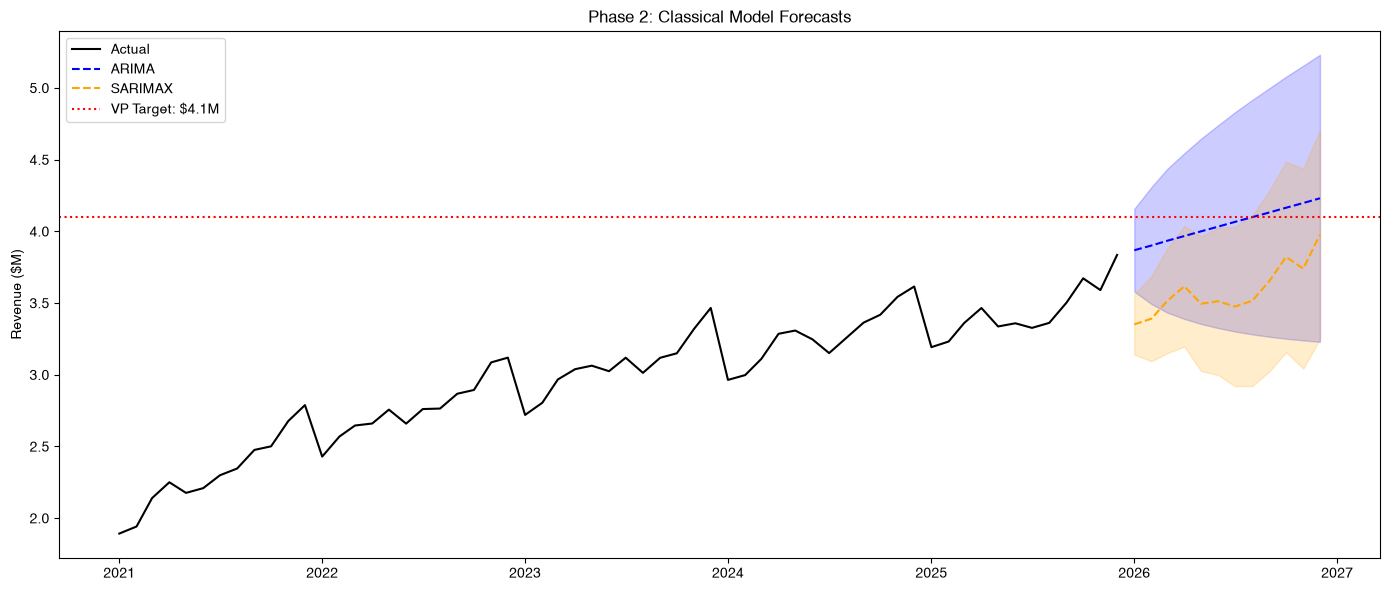

In [116]:
# Plot with prediction intervals
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(revenue.index, revenue / 1e6, 'k-', label='Actual')

ax.plot(fc_index, arima_mean / 1e6, 'b--', label='ARIMA')
ax.fill_between(fc_index, arima_ci.iloc[:, 0] / 1e6, arima_ci.iloc[:, 1] / 1e6, 
                color='blue', alpha=0.2)

ax.plot(fc_index, sarimax_mean / 1e6, 'orange', linestyle='--', label='SARIMAX')
ax.fill_between(fc_index, sarimax_ci.iloc[:, 0] / 1e6, sarimax_ci.iloc[:, 1] / 1e6,
                color='orange', alpha=0.2)

ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 2: Classical Model Forecasts')
ax.legend()
plt.tight_layout()
plt.show()

---

## Phase 3: Modern Models

Train N-BEATS and run Chronos-2 using Darts.

In [320]:
ts = TimeSeries.from_dataframe(
    df.reset_index(), 
    time_col='date', 
    value_cols='revenue', 
    freq='MS'
)

train_ts, test_ts = ts.split_before(pd.Timestamp('2025-01-01'))

print(f"Train: {len(train_ts)} months")
print(f"Test: {len(test_ts)} months")

Train: 48 months
Test: 12 months


In [321]:
nbeats = NBEATSModel(
    input_chunk_length=36,
    output_chunk_length=12,
    n_epochs=100,
    random_state=42,
    pl_trainer_kwargs={"accelerator": "cpu"},
)

nbeats.fit(train_ts)

nbeats_pred = nbeats.predict(len(test_ts), series=train_ts)
nbeats_mae = mae(test_ts, nbeats_pred)
nbeats_rmse = rmse(test_ts, nbeats_pred)

print(f"N-BEATS Test MAE: ${nbeats_mae:,.0f}")
print(f"N-BEATS Test RMSE: ${nbeats_rmse:,.0f}")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name            | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train | 0    
1 | train_criterion | MSELoss          | 0      | train | 0    
2 | val_criterion   | MSELoss          | 0      | train | 0    
3 | train_metrics   | MetricCollection | 0      | train | 0    
4 | val_metrics     | MetricCollection | 0      | train | 0    
5 | stacks          | ModuleList       | 6.3 M  | train | 0    
---------------------------------------------------------------------
6.3 M     Trainable params
1.5 K     Non-trainable params
6.3 M     Total params
50.329    Total esti

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Predicting: |          | 0/? [00:00<?, ?it/s]

N-BEATS Test MAE: $195,624
N-BEATS Test RMSE: $210,981


In [322]:
nbeats = NBEATSModel(
    input_chunk_length=48,
    output_chunk_length=12,
    n_epochs=100,
    likelihood=QuantileRegression([0.05, 0.5, 0.95]),
    random_state=42,
    pl_trainer_kwargs={"accelerator": "cpu"},
)
nbeats.fit(ts)
nbeats_fc = nbeats.predict(n=HORIZON, series=ts, num_samples=1000)
nbeats_dec_2026 = nbeats_fc.values()[-1, 0]
nbeats_lower_2026_lower = nbeats_fc.quantile(0.05).values()[-1, 0]
nbeats_dec_2026_upper = nbeats_fc.quantile(0.95).values()[-1, 0]

print(f"Dec 2026 forecast: ${nbeats_dec_2026/1e6:.2f}M")
print(f"90% CI: [${nbeats_lower_2026_lower/1e6:.2f}M, ${nbeats_dec_2026_upper/1e6:.2f}M]")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name            | Type             | Params | Mode  | FLOPs
---------------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train | 0    
1 | train_criterion | MSELoss          | 0      | train | 0    
2 | val_criterion   | MSELoss          | 0      | train | 0    
3 | train_metrics   | MetricCollection | 0      | train | 0    
4 | val_metrics     | MetricCollection | 0      | train | 0    
5 | stacks          | ModuleList       | 6.5 M  | train | 0    
---------------------------------------------------------------------
6.5 M     Trainable params
1.6 K     Non-trainable params
6.5 M     Total params
51.701    Total esti

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Predicting: |          | 0/? [00:00<?, ?it/s]

Dec 2026 forecast: $4.17M
90% CI: [$4.12M, $5.14M]


In [323]:
from darts.models import Chronos2Model

chronos = Chronos2Model(
    input_chunk_length=36,
    output_chunk_length=12,
    model_name='amazon/chronos-2',
    pl_trainer_kwargs={"accelerator": "cpu"},
)
chronos.fit(train_ts)
chronos_pred = chronos.predict(n=len(test_ts), series=train_ts)
chronos_mae = mae(test_ts, chronos_pred)
chronos_rmse = rmse(test_ts, chronos_pred)

print(f"Chronos-2 Test MAE: ${chronos_mae:,.0f}")
print(f"Chronos-2 Test RMSE: ${chronos_rmse:,.0f}")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Predicting: |          | 0/? [00:00<?, ?it/s]

Chronos-2 Test MAE: $87,459
Chronos-2 Test RMSE: $116,471


In [324]:
chronos = Chronos2Model(
    input_chunk_length=48,
    output_chunk_length=12,
    model_name='amazon/chronos-2',
    likelihood=QuantileRegression([0.05, 0.5, 0.95]),
    pl_trainer_kwargs={"accelerator": "cpu"},
)
chronos.fit(ts)
chronos_fc = chronos.predict(n=HORIZON, series=ts, predict_likelihood_parameters=True)
# Components are in the order of the quantiles given above: 0.05, 0.5, 0.95
chronos_dec_2026_lower = chronos_fc.values()[-1, 0]
chronos_dec_2026 = chronos_fc.values()[-1, 1]
chronos_dec_2026_upper = chronos_fc.values()[-1, 2]

print(f"Chronos-2 Dec 2026: ${chronos_dec_2026/1e6:.2f}M")
print(f"90% CI: [${chronos_dec_2026_lower/1e6:.2f}M, ${chronos_dec_2026_upper/1e6:.2f}M]")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Predicting: |          | 0/? [00:00<?, ?it/s]

Chronos-2 Dec 2026: $3.93M
90% CI: [$3.58M, $4.17M]


---

## Phase 4: Comparison and Recommendation

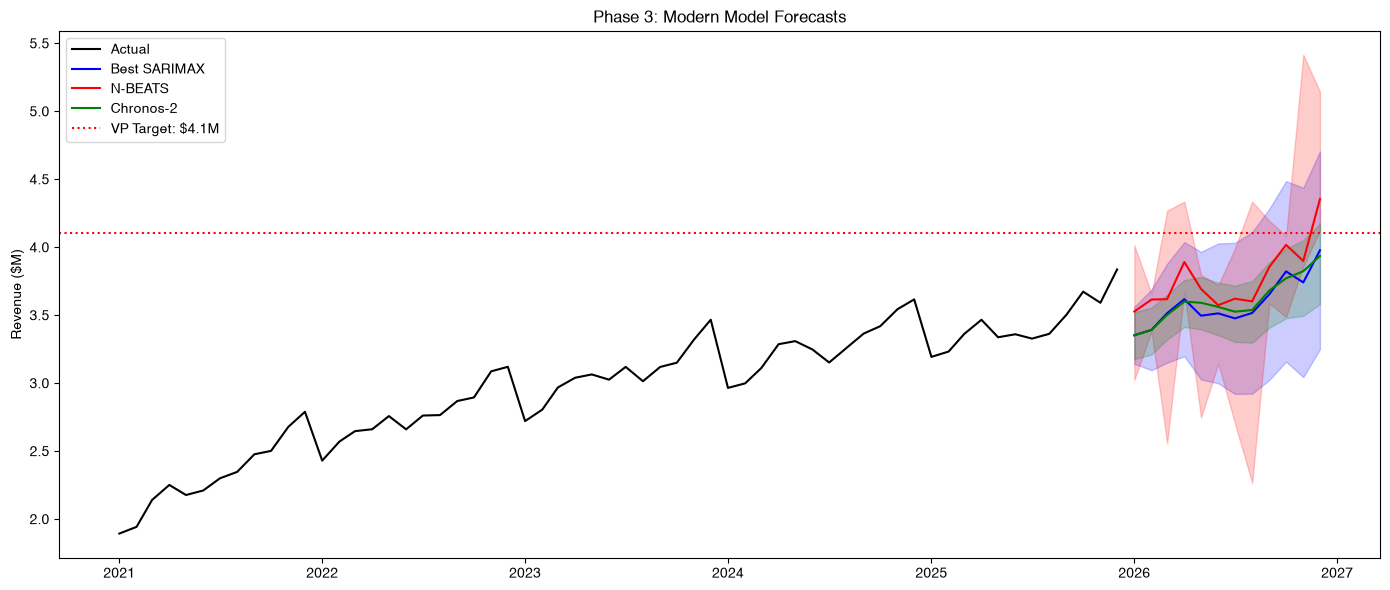

In [325]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(revenue.index, revenue / 1e6, color='black', label='Actual')

date_index = pd.date_range('2026-01-01', periods=HORIZON, freq='MS')
ax.plot(sarimax_mean / 1e6, color='blue', label='Best SARIMAX')
ax.fill_between(date_index, sarimax_ci.iloc[:, 0] / 1e6, sarimax_ci.iloc[:, 1] / 1e6, color='blue', alpha=0.2)
ax.plot(nbeats_fc.quantile(0.5).to_dataframe() / 1e6, color='red', label='N-BEATS')
ax.fill_between(date_index, nbeats_fc.quantile(0.05).values().flatten() / 1e6, nbeats_fc.quantile(0.95).values().flatten() / 1e6, color='red', alpha=0.2)
ax.plot(chronos_fc.to_dataframe().iloc[:, 1] / 1e6, color='green', label='Chronos-2')
ax.fill_between(date_index, chronos_fc.to_dataframe().iloc[:, 0].values / 1e6, chronos_fc.to_dataframe().iloc[:, 2].values / 1e6, color='green', alpha=0.2)

ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 3: Modern Model Forecasts')
ax.legend()
plt.tight_layout()
plt.show()

In [326]:
target = 4.1

comparison_data = {
    'Model': ['Naive', '6MA', '12MA', 'Trend', 'ARIMA', 'SARIMAX', 'N-BEATS', 'Chronos-2'],
    'Dec 2026 Forecast': [
        forecasts['Naive'].iloc[-1],
        forecasts['6MA'].iloc[-1],
        forecasts['12MA'].iloc[-1],
        forecasts['Trend'].iloc[-1],
        arima_dec_2026,
        sarimax_dec_2026,
        nbeats_dec_2026,
        chronos_dec_2026
    ],
    '95% CI Lower': [
        forecasts['Naive'].iloc[-1],
        forecasts['6MA'].iloc[-1],
        forecasts['12MA'].iloc[-1],
        forecasts['Trend'].iloc[-1],
        arima_lower,
        sarimax_lower,
        nbeats_lower_2026_lower,
        chronos_dec_2026_lower
    ],
    '95% CI Upper': [
        forecasts['Naive'].iloc[-1],
        forecasts['6MA'].iloc[-1],
        forecasts['12MA'].iloc[-1],
        forecasts['Trend'].iloc[-1],
        arima_upper,
        sarimax_upper,
        nbeats_dec_2026_upper,
        chronos_dec_2026_upper
    ],
    'Test MAE': [
        np.mean(np.abs(forecasts['Naive'].values - test.values)) / 1e6,
        np.mean(np.abs(forecasts['6MA'].values - test.values)) / 1e6,
        np.mean(np.abs(forecasts['12MA'].values - test.values)) / 1e6,
        np.mean(np.abs(forecasts['Trend'].values - test.values)) / 1e6,
        arima_mae / 1e6,
        sarimax_mae / 1e6,
        nbeats_mae / 1e6,
        chronos_mae / 1e6
    ],
    'P(Reach $4.1M)': [
        1 if forecasts['Naive'].iloc[-1] / 1e6 > target else 0,
        1 if forecasts['6MA'].iloc[-1] / 1e6 > target else 0,
        1 if forecasts['12MA'].iloc[-1] / 1e6 > target else 0,
        1 if forecasts['Trend'].iloc[-1] / 1e6 > target else 0,
        arima_prob,
        sarimax_prob,
        prob_above_target(nbeats_dec_2026, nbeats_dec_2026_upper, target, alpha=0.05),
        prob_above_target(chronos_dec_2026, chronos_dec_2026_upper, target, alpha=0.05),
    ]
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df['Dec 2026 Forecast'] = comparison_df['Dec 2026 Forecast'] / 1e6
comparison_df['95% CI Lower'] = comparison_df['95% CI Lower'] / 1e6
comparison_df['95% CI Upper'] = comparison_df['95% CI Upper'] / 1e6

print(comparison_df.to_string(index=False))

    Model  Dec 2026 Forecast  95% CI Lower  95% CI Upper  Test MAE  P(Reach $4.1M)
    Naive           3.834907      3.834907      3.834907  0.399056        0.000000
      6MA           3.547799      3.547799      3.547799  0.187520        0.000000
     12MA           3.435851      3.435851      3.435851  0.147440        0.000000
    Trend           3.975722      3.975722      3.975722  0.406553        0.000000
    ARIMA           4.230036      3.229296      5.230777  0.417258        0.600514
  SARIMAX           3.976217      3.248699      4.703735  0.068335        0.369387
  N-BEATS           4.174774      4.120484      5.142159  0.195624        1.000000
Chronos-2           3.934427      3.580450      4.174034  0.087459        1.000000


### Written Recommendation

Write a 500–1000 word stakeholder-ready recommendation addressing:

1. **What is the realistic range for December 2026 revenue?**
   - Based on model forecasts and prediction intervals
   - Consider the spread across different approaches

2. **What should the company plan for?**
   - Provide a specific target or range based on your analysis
   - Explain the gap between models and the VP's original $4.1M target
   - Discuss probability of achieving different revenue levels

3. **Which forecasting approach would you recommend for ongoing use, and why?**
   - Compare accuracy, interpretability, and practical considerations
   - Consider maintenance requirements and stakeholder understanding
   - Recommend a specific approach with justification

**YOUR WRITTEN RECOMMENDATION (500–1000 words):**

[Write your recommendation here...]